In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/kelmarsh1_2023_propre.csv", index_col=0, parse_dates=True)
print(df.shape)

(52560, 15)


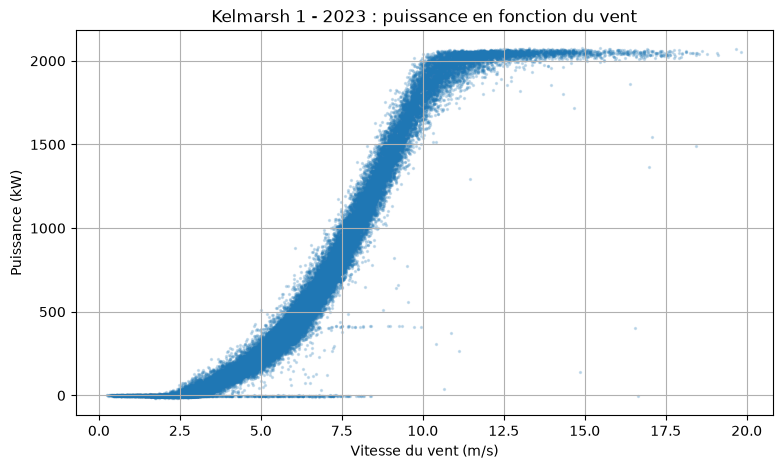

In [2]:
d = df[["Wind speed (m/s)", "Power (kW)"]].dropna().copy()

plt.figure(figsize=(9, 5))
plt.scatter(d["Wind speed (m/s)"], d["Power (kW)"], s=2, alpha=0.2)
plt.xlabel("Vitesse du vent (m/s)")
plt.ylabel("Puissance (kW)")
plt.title("Kelmarsh 1 - 2023 : puissance en fonction du vent")
plt.grid(True)
plt.savefig("j2_nuage_puissance.png", dpi=150, bbox_inches="tight")
plt.show()

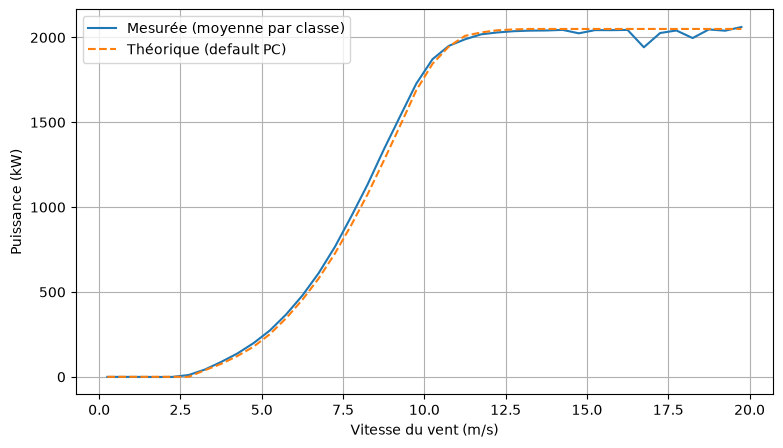

In [3]:
d["classe"] = (d["Wind speed (m/s)"] // 0.5) * 0.5 + 0.25
courbe = d.groupby("classe")["Power (kW)"].agg(["mean", "std", "count"])

th = df[["Wind speed (m/s)", "Potential power default PC (kW)"]].dropna().copy()
th["classe"] = (th["Wind speed (m/s)"] // 0.5) * 0.5 + 0.25
courbe_th = th.groupby("classe")["Potential power default PC (kW)"].mean()

plt.figure(figsize=(9, 5))
plt.plot(courbe.index, courbe["mean"], label="Mesurée (moyenne par classe)")
plt.plot(courbe_th.index, courbe_th, "--", label="Théorique (default PC)")
plt.xlabel("Vitesse du vent (m/s)")
plt.ylabel("Puissance (kW)")
plt.legend()
plt.grid(True)
plt.savefig("j2_courbe_mesuree_vs_theorique.png", dpi=150, bbox_inches="tight")
plt.show()

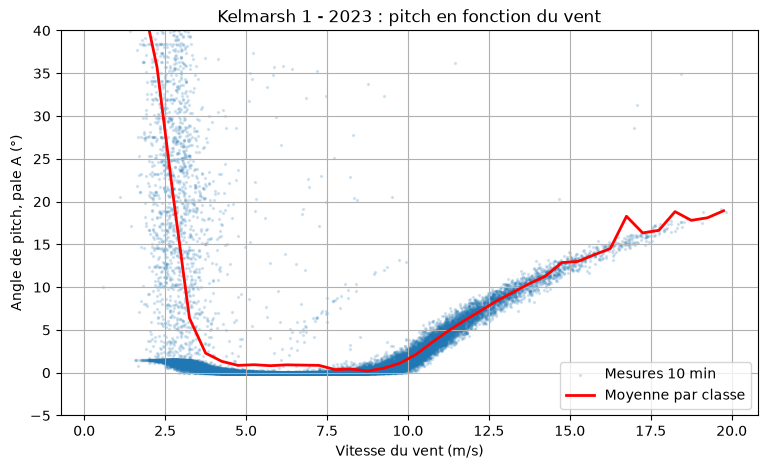

In [4]:
p = df[["Wind speed (m/s)", "Blade angle (pitch position) A (°)"]].dropna().copy()
p.columns = ["vent", "pitch"]
p["classe"] = (p["vent"] // 0.5) * 0.5 + 0.25
moy = p.groupby("classe")["pitch"].mean()

plt.figure(figsize=(9, 5))
plt.scatter(p["vent"], p["pitch"], s=2, alpha=0.15, label="Mesures 10 min")
plt.plot(moy.index, moy.values, color="red", linewidth=2, label="Moyenne par classe")
plt.xlabel("Vitesse du vent (m/s)")
plt.ylabel("Angle de pitch, pale A (°)")
plt.title("Kelmarsh 1 - 2023 : pitch en fonction du vent")
plt.ylim(-5, 40)
plt.grid(True)
plt.legend()
plt.savefig("j2_pitch_vs_vent.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
import numpy as np

c = df[["Wind speed (m/s)", "Power (kW)"]].dropna().copy()
c = c[(c["Wind speed (m/s)"] > 3) & (c["Power (kW)"] > 0)]
rho, A = 1.225, np.pi * 46**2
c["Cp"] = c["Power (kW)"] * 1000 / (0.5 * rho * A * c["Wind speed (m/s)"]**3)

print(c["Cp"].describe())
print("Lignes avec Cp > 0,593 :", (c["Cp"] > 0.593).sum())

count    46075.000000
mean         0.449936
std          0.102475
min          0.000644
25%          0.405370
50%          0.463602
75%          0.510081
max          1.290849
Name: Cp, dtype: float64
Lignes avec Cp > 0,593 : 1917


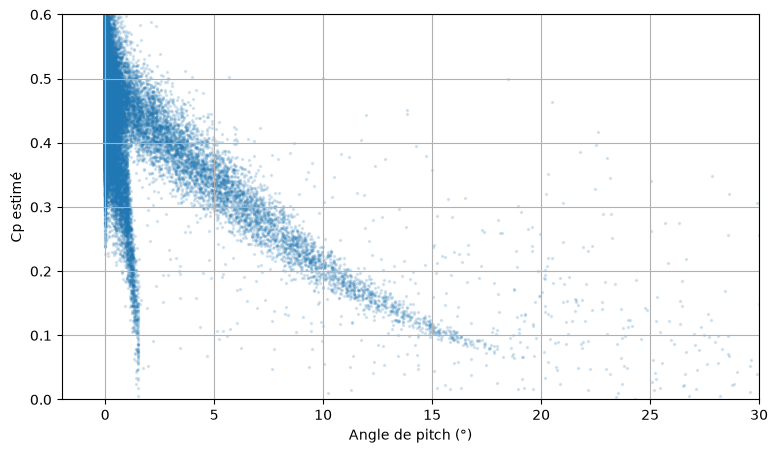

In [6]:
import numpy as np
c = df[["Wind speed (m/s)", "Power (kW)", "Blade angle (pitch position) A (°)"]].dropna().copy()
c = c[(c["Wind speed (m/s)"] > 3) & (c["Power (kW)"] > 0)]
rho, A = 1.225, np.pi * 46**2
c["Cp"] = c["Power (kW)"] * 1000 / (0.5 * rho * A * c["Wind speed (m/s)"]**3)

plt.figure(figsize=(9, 5))
plt.scatter(c["Blade angle (pitch position) A (°)"], c["Cp"], s=2, alpha=0.15)
plt.xlabel("Angle de pitch (°)"); plt.ylabel("Cp estimé")
plt.xlim(-2, 30); plt.ylim(0, 0.6); plt.grid(True)
plt.savefig("j2_cp_vs_pitch.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
out = courbe[["mean"]].join(courbe_th.rename("theorique"))
out.columns = ["mesuree", "theorique"]
out.index.name = "vent"
out.round(1).to_csv("j2_courbe_pour_powerbi.csv")

In [8]:
p = df[["Wind speed (m/s)", "Blade angle (pitch position) A (°)", "Power (kW)"]].dropna()
p = p[p["Power (kW)"] > 0]   # turbine en production seulement
p["classe"] = (p["Wind speed (m/s)"] // 0.5) * 0.5 + 0.25
pitch = p.groupby("classe")["Blade angle (pitch position) A (°)"].mean().rename("pitch")
pitch.index.name = "vent"
pitch.round(2).to_csv("j2_pitch_pour_powerbi.csv")
print(pitch.shape)

(37,)
